# CISC7204 Team Project — Crime and House Prices in London Boroughs

**Team 05** · CISC7204 Data Science and Data Visualization, 2026/2027 Semester 1

This notebook rebuilds the borough-year panel from the two working files and runs every
comparison quoted in the report:

1. the baseline cross-section (ρ = 0.47)
2. the same cross-section with median earnings partialled out
3. a denominator sweep (residents + k × jobs)
4. inner / outer London
5. within-borough year-to-year changes
6. lead and lag
7. leave-one-out
8. offence types (MPS borough file)
9. a cross-validation of the two crime totals

Inputs (`data/`, paths relative to this folder):

| file | content |
|---|---|
| `housing_in_london_monthly.csv` | monthly price, sales, crime total per area |
| `housing_in_london_yearly.csv` | yearly population, median earnings, jobs |
| `MPS_Borough_Level_Crime_Historical.csv` | MPS recorded crime by offence, borough, month |

Every figure is written to `figures/analysis/`. Running this notebook from a clean kernel
regenerates every number in the report.

In [1]:
# ============================================================
# 依赖与路径设置
# 只需要 numpy / pandas / matplotlib
# ============================================================
from pathlib import Path

import matplotlib
matplotlib.use("Agg")            # 不弹窗，直接把图存成文件
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 路径按「相对本 notebook 所在目录」解析，符合 Table 14 的约定
ROOT = Path.cwd()
DATA = ROOT / "data"
FIG = ROOT / "figures" / "analysis"
FIG.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

print("data folder :", DATA.relative_to(ROOT))
print("figure out  :", FIG.relative_to(ROOT))

data folder : data
figure out  : figures/analysis


## 0. Helper functions

Small, explicit implementations so that every coefficient in the report can be traced
to one function. `spearman` ranks first and then takes a Pearson correlation of the
ranks; `partial_spearman` residualises both rank series on the rank of the control.

In [2]:
# ============================================================
# 统计工具函数
# 全部手写，避免依赖 scipy，也方便逐行核对口径
# ============================================================

def spearman(x, y):
    '''Spearman 秩相关：先把 x、y 转成平均秩，再算 Pearson 相关。'''
    x = pd.Series(np.asarray(x, dtype=float))
    y = pd.Series(np.asarray(y, dtype=float))
    return float(x.rank(method="average").corr(y.rank(method="average")))


def perm_p(x, y, n=5000, seed=0):
    '''置换检验的双尾 p 值：打乱 y 重算 rho，看有多少次不小观测值。'''
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    obs = abs(spearman(x, y))
    rng = np.random.default_rng(seed)
    hits = sum(abs(spearman(x, rng.permutation(y))) >= obs - 1e-12 for _ in range(n))
    return (hits + 1) / (n + 1)


def partial_spearman(x, y, z):
    '''偏 Spearman：把 x、y 的秩各自对 z 的秩回归，取残差再算相关。'''
    rx = pd.Series(x).rank(method="average").to_numpy()
    ry = pd.Series(y).rank(method="average").to_numpy()
    rz = pd.Series(z).rank(method="average").to_numpy()

    def resid(v):
        A = np.column_stack([np.ones_like(rz), rz])       # 截距 + 控制变量
        beta, *_ = np.linalg.lstsq(A, v, rcond=None)
        return v - A @ beta                               # 回归残差

    return float(np.corrcoef(resid(rx), resid(ry))[0, 1])


def boot_ci(x, y, groups=None, n=3000, seed=1):
    '''百分位 bootstrap 置信区间。
    给了 groups 就按 group 做整块重抽样（区内的年度对不能当独立样本）。'''
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    rng = np.random.default_rng(seed)
    vals = []
    if groups is None:
        idx = np.arange(len(x))
        for _ in range(n):
            s = rng.choice(idx, size=len(idx), replace=True)
            if len(np.unique(x[s])) > 5:
                vals.append(spearman(x[s], y[s]))
    else:
        g = np.asarray(groups)
        uniq = np.unique(g)
        pos = {k: np.where(g == k)[0] for k in uniq}
        for _ in range(n):
            pick = rng.choice(uniq, size=len(uniq), replace=True)
            sel = np.concatenate([pos[k] for k in pick])
            vals.append(spearman(x[sel], y[sel]))
    v = np.array(vals)
    return float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))


def ols_line(x, y):
    '''最小二乘直线，只用来做视觉引导，不用于预测。'''
    b, a = np.polyfit(x, y, 1)
    xs = np.linspace(np.min(x), np.max(x), 50)
    return xs, a + b * xs


# ---------- 统一绘图风格 ----------
INK, MUTED, GRID = "#1c1c1c", "#6b6b6b", "#d8d8d8"
BLUE, TERRA, GOLD = "#2b5797", "#c65f2e", "#c99a2e"

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "savefig.facecolor": "white", "font.family": "DejaVu Sans",
    "font.size": 10.5, "axes.titlesize": 13, "axes.labelsize": 10.5,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linestyle": ":", "grid.linewidth": 0.7,
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 170,
})


def tidy(ax, axis="both"):
    '''统一的网格与轴样式。'''
    ax.grid(True, axis=axis, alpha=0.85)
    ax.set_axisbelow(True)
    for s in ("left", "bottom"):
        ax.spines[s].set_linewidth(0.9)
        ax.spines[s].set_color(MUTED)


from IPython.display import Image, display


def save(fig, name):
    '''存图 + 在 notebook 里直接显示，方便核对和作为提交凭证。'''
    path = FIG / name
    fig.savefig(path, dpi=170, bbox_inches="tight")
    plt.close(fig)
    print("saved", name)
    display(Image(filename=str(path)))


print("helpers ready")

helpers ready


## 1. Load the two working files

`no_of_crimes` is blank before January 2001, and `average_price` is a monthly mean.
`borough_flag == 1` keeps the 32 boroughs plus the City of London.

In [3]:
# ============================================================
# 读入两份原始表，并加一个 year 列方便聚合
# ============================================================
monthly = pd.read_csv(DATA / "housing_in_london_monthly.csv")
yearly = pd.read_csv(DATA / "housing_in_london_yearly.csv")

monthly["date"] = pd.to_datetime(monthly["date"])
yearly["date"] = pd.to_datetime(yearly["date"])
monthly["year"] = monthly["date"].dt.year
yearly["year"] = yearly["date"].dt.year

print("monthly", monthly.shape, "|", monthly["date"].min().date(), "to", monthly["date"].max().date())
print("yearly ", yearly.shape, "|", yearly["date"].min().date(), "to", yearly["date"].max().date())
print()
print("monthly columns:", list(monthly.columns))
print("yearly  columns:", list(yearly.columns))

monthly (13549, 8) | 1995-01-01 to 2020-01-01
yearly  (1071, 13) | 1999-12-01 to 2019-12-01

monthly columns: ['date', 'area', 'average_price', 'code', 'houses_sold', 'no_of_crimes', 'borough_flag', 'year']
yearly  columns: ['code', 'area', 'date', 'median_salary', 'life_satisfaction', 'mean_salary', 'recycling_pct', 'population_size', 'number_of_jobs', 'area_size', 'no_of_houses', 'borough_flag', 'year']


In [4]:
# 犯罪字段从哪一年开始有值？—— 决定面板起点
crime_by_year = (
    monthly[monthly["borough_flag"] == 1]
    .assign(has_crime=lambda d: d["no_of_crimes"].notna())
    .groupby("year")["has_crime"].sum()
)
print("犯罪字段有值的年份：",
      crime_by_year[crime_by_year > 0].index.min(), "–",
      crime_by_year[crime_by_year > 0].index.max(),
      "（2020 年只有 1 月一个月，不成一个年度）")

犯罪字段有值的年份： 2001 – 2020 （2020 年只有 1 月一个月，不成一个年度）


## 2. Build the borough-year panel

Rules (the same ones written into Table 7 of the proposal):

* keep `borough_flag == 1`
* price is the mean of the monthly values, crime is the sum of the monthly totals
* `crime_months` counts the months that actually carry a crime total
* a borough-year enters only if `crime_months >= 10` and population is present

In [5]:
# ============================================================
# 月度 → 年度：房价取均值，犯罪数求和，并统计有犯罪记录的月份数
# ============================================================
m = monthly[monthly["borough_flag"] == 1].copy()
agg = m.groupby(["area", "year"], as_index=False).agg(
    avg_price=("average_price", "mean"),       # 年均房价
    crimes=("no_of_crimes", "sum"),            # 年犯罪总数
    crime_months=("no_of_crimes", "count"),    # 有犯罪记录的月份数
    sold=("houses_sold", "mean"),              # 月均成交量（只作质量标记）
)

# 年度表只留需要的列，并统一转成数值
y = yearly[yearly["borough_flag"] == 1][
    ["area", "year", "population_size", "median_salary", "number_of_jobs", "no_of_houses"]
].copy()
for c in ["population_size", "median_salary", "number_of_jobs", "no_of_houses"]:
    y[c] = pd.to_numeric(y[c], errors="coerce")

panel = agg.merge(y, on=["area", "year"], how="left")

# 核心变量：每千人犯罪率
panel["crime_per_1000"] = panel["crimes"] / panel["population_size"] * 1000

# 入库规则：犯罪月份 ≥ 10，且有房价、有人口（没有人口就构不成率）
panel = panel[
    (panel["crime_months"] >= 10)
    & panel["avg_price"].notna()
    & panel["population_size"].notna()
].sort_values(["area", "year"]).reset_index(drop=True)

print("panel size:", panel.shape)
print("years     :", panel["year"].min(), "-", panel["year"].max())
print("boroughs per year:")
print(panel.groupby("year")["area"].nunique().to_string())
panel.head()

panel size: (585, 11)
years     : 2001 - 2018
boroughs per year:
year
2001    33
2002    33
2003    33
2004    33
2005    33
2006    33
2007    33
2008    33
2009    33
2010    32
2011    32
2012    32
2013    32
2014    32
2015    32
2016    32
2017    32
2018    32


,area,year,avg_price,crimes,crime_months,sold,population_size,median_salary,number_of_jobs,no_of_houses,crime_per_1000
0,barking and dagenham,2001,88664.000000,20476.0,12,266.916667,165654.0,22323.0,54000.0,68298.0,123.607036
1,barking and dagenham,2002,112221.916667,20040.0,12,287.416667,166357.0,24813.0,52000.0,68526.0,120.463822
2,barking and dagenham,2003,142499.000000,21085.0,12,301.250000,166210.0,25358.0,55000.0,68837.0,126.857590
3,barking and dagenham,2004,158176.000000,21271.0,12,301.333333,165610.0,26089.0,53000.0,68899.0,128.440312
4,barking and dagenham,2005,163360.916667,20715.0,12,240.833333,166275.0,26680.0,53000.0,69261.0,124.582770


### Why the panel stops at 2018

Crime is populated through December 2019, but the annual file has **no population and no
jobs for 2019**. A rate needs a denominator, so 2019 cannot enter the rate panel.
This is the boundary the report has to state.

In [6]:
# ============================================================
# 核查面板为什么停在 2018：犯罪月份有，但分母缺失
# ============================================================
raw = agg.merge(y, on=["area", "year"], how="left")
check = raw[raw["crimes"].notna()].groupby("year").agg(
    crime_months=("crime_months", "max"),
    population_present=("population_size", "count"),
    jobs_present=("number_of_jobs", "count"),
)
check.loc[[2016, 2017, 2018, 2019]].assign(areas=33)

,crime_months,population_present,jobs_present,areas
year,,,,
2016,12,33,33,33
2017,12,33,33,33
2018,12,33,33,33
2019,12,0,0,33


## 3. The cross-section: 2016–2018 borough means

This is the comparison the first draft reported. If the common-sense claim held, the
rank correlation between the crime rate and the average price would be **negative**.

In [7]:
# ============================================================
# 横截面：把 2016–2018 三年压成每个区一行
# 要求三年都在样本里（n_years == 3），否则均值的口径不一致
# ============================================================
win = panel[panel["year"].between(2016, 2018)]
cs = win.groupby("area", as_index=False).agg(
    price=("avg_price", "mean"),
    rate=("crime_per_1000", "mean"),
    counts=("crimes", "mean"),
    pop=("population_size", "mean"),
    jobs=("number_of_jobs", "mean"),
    salary=("median_salary", "mean"),
    sold=("sold", "mean"),
    n_years=("year", "nunique"),
)

INNER = {
    "camden", "islington", "hammersmith and fulham", "hackney", "haringey",
    "southwark", "lambeth", "tower hamlets", "wandsworth", "westminster",
    "kensington and chelsea",
}

cs = cs[(cs["n_years"] == 3)].dropna(subset=["price", "rate", "salary", "jobs"]).reset_index(drop=True)
cs["rate_day"] = cs["counts"] / (cs["pop"] + cs["jobs"]) * 1000   # 白天暴露口径
cs["jobs_ratio"] = cs["jobs"] / cs["pop"]                          # 就业密度
cs["inner"] = cs["area"].isin(INNER)

print("n =", len(cs), "boroughs")
cs[["area", "price", "rate", "salary", "jobs_ratio"]].round(2).head(8)

n = 32 boroughs


,area,price,rate,salary,jobs_ratio
0,barking and dagenham,285617.08,86.85,29847.33,0.31
1,barnet,532495.61,69.43,31564.33,0.44
2,bexley,333287.22,59.07,30733.00,0.36
3,brent,490006.17,89.24,30399.67,0.47
4,bromley,437545.61,67.59,30480.67,0.40
5,camden,829625.67,136.10,38387.33,1.57
6,croydon,366233.17,79.67,32464.00,0.39
7,ealing,480361.11,82.27,29809.33,0.47


In [8]:
# ============================================================
# 基线比较：六对变量的秩相关 + 置换检验 p 值
# ============================================================
pairs = [
    ("crime rate vs price",             "rate",       "price"),
    ("crime count vs price",            "counts",     "price"),
    ("median earnings vs price",        "salary",     "price"),
    ("crime rate vs median earnings",   "rate",       "salary"),
    ("jobs per resident vs price",      "jobs_ratio", "price"),
    ("jobs per resident vs crime rate", "jobs_ratio", "rate"),
]

rows = []
for label, a, b in pairs:
    rows.append({
        "comparison": label,
        "spearman": round(spearman(cs[a], cs[b]), 3),
        "perm_p": round(perm_p(cs[a], cs[b], n=5000, seed=7), 4),
        "n": len(cs),
    })
baseline = pd.DataFrame(rows)
baseline

,comparison,spearman,perm_p,n
0,crime rate vs price,0.470,0.0084,32
1,crime count vs price,0.252,0.1680,32
2,median earnings vs price,0.512,0.0036,32
3,crime rate vs median earnings,0.589,0.0004,32
4,jobs per resident vs price,0.655,0.0002,32
5,jobs per resident vs crime rate,0.508,0.0034,32


The first row reproduces the 0.47 in the first draft, so the panel and the join are right.
The **sign is positive**: on this cross-section the claim does not hold. Rows 3 to 6 are
the reason not to stop there.

## 4. Figure 1 — the baseline scatter

The figure the first draft is built on. Price against the crime rate, coloured by median
earnings, with an OLS line drawn as a visual guide only.

saved fig1_baseline.png


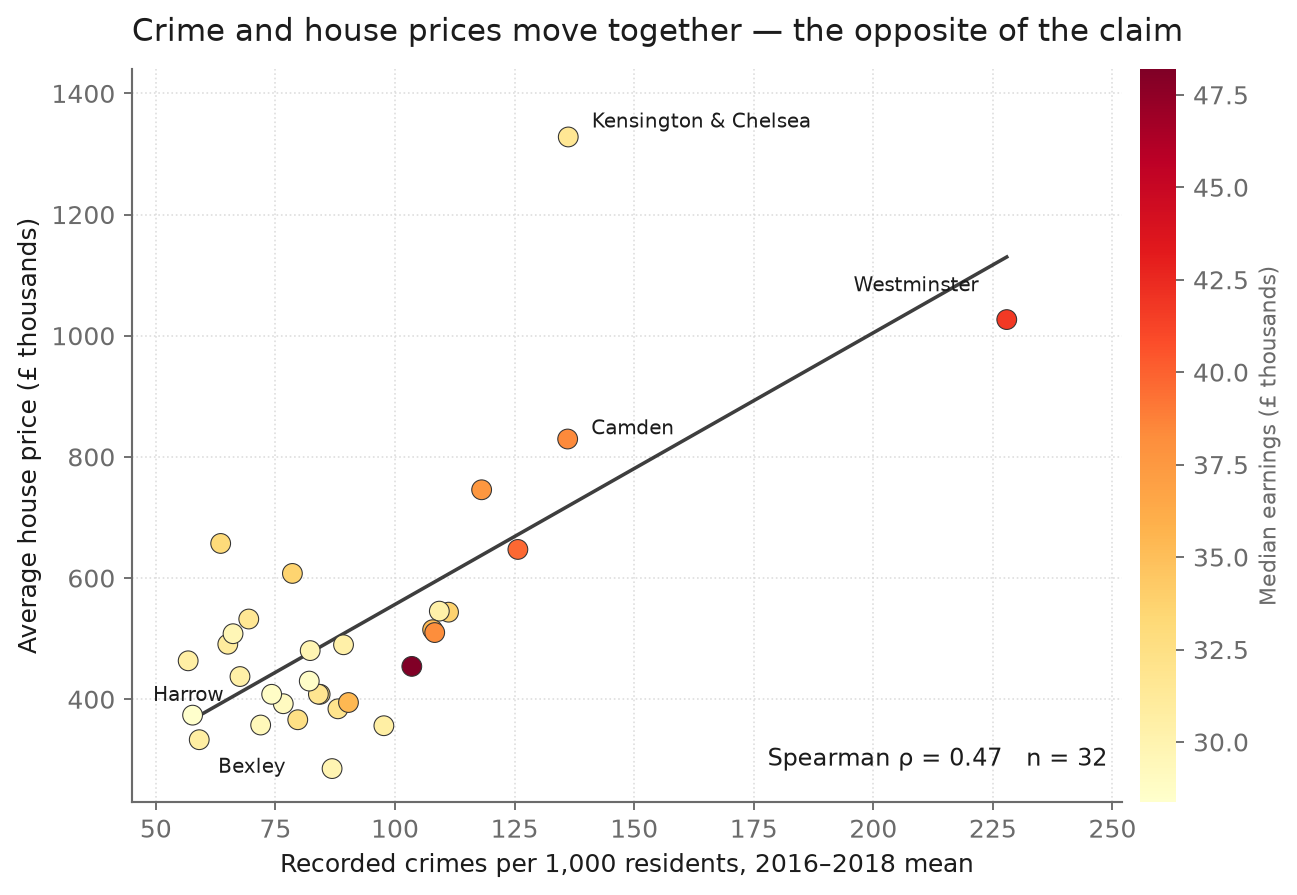

In [9]:
# ============================================================
# Figure 1：基线散点（颜色 = 工资），只用于讲清「方向反了」
# ============================================================
fig, ax = plt.subplots(figsize=(9.0, 5.6))
sc = ax.scatter(cs["rate"], cs["price"] / 1000, c=cs["salary"] / 1000,
                cmap="YlOrRd", s=70, edgecolor="#333333", linewidth=0.45, zorder=3)
xs, ys = ols_line(cs["rate"], cs["price"] / 1000)
ax.plot(xs, ys, color=INK, lw=1.5, zorder=2, alpha=0.85)

def pretty(a):
    '''把 'kensington and chelsea' 变成 'Kensington & Chelsea'。'''
    s = a.replace(" and ", " & ")
    return " ".join(w.capitalize() if w not in ("&", "of", "upon") else w for w in s.split())

for name, dx, dy, ha in [("westminster", -12, 12, "right"),
                         ("kensington and chelsea", 10, 4, "left"),
                         ("bexley", 8, -14, "left"),
                         ("harrow", 0, -17, "center"),
                         ("camden", 10, 2, "left")]:
    r = cs[cs["area"] == name].iloc[0]
    ax.annotate(pretty(name), xy=(r["rate"], r["price"] / 1000), xytext=(dx, dy),
                textcoords="offset points", fontsize=8.5, color=INK, ha=ha)

cb = fig.colorbar(sc, ax=ax, pad=0.015)
cb.set_label("Median earnings (£ thousands)", color=MUTED, fontsize=9.5)
cb.outline.set_visible(False)
ax.set_xlabel("Recorded crimes per 1,000 residents, 2016–2018 mean")
ax.set_ylabel("Average house price (£ thousands)")
ax.set_xlim(45, 252); ax.set_ylim(230, 1440)
ax.set_title("Crime and house prices move together — the opposite of the claim", loc="left", pad=12)
ax.text(0.985, 0.05, f"Spearman ρ = {spearman(cs['rate'], cs['price']):.2f}   n = {len(cs)}",
        transform=ax.transAxes, ha="right", fontsize=10)
tidy(ax)
save(fig, "fig1_baseline.png")

## 5. Earnings sit on both sides

Median earnings correlate with price (0.51) **and** with the crime rate (0.59). A
borough that is merely richer will therefore look like a borough with more crime and a
higher price. Partialling earnings out of the ranks is the first test.

In [10]:
# ============================================================
# 偏相关：把工资的秩从犯罪率和房价里各自扣掉，看剩下多少关联
# ============================================================
r_raw   = spearman(cs["rate"], cs["price"])
r_part  = partial_spearman(cs["rate"], cs["price"], cs["salary"])
r_day   = spearman(cs["rate_day"], cs["price"])
r_day_p = partial_spearman(cs["rate_day"], cs["price"], cs["salary"])
lo, hi  = boot_ci(cs["rate"], cs["price"])

print(f"crime rate vs price               rho = {r_raw:.3f}   95% CI [{lo:.3f}, {hi:.3f}]")
print(f"  ... with earnings partialled     rho = {r_part:.3f}")
print(f"crime rate / (residents + jobs)   rho = {r_day:.3f}")
print(f"  ... with earnings partialled     rho = {r_day_p:.3f}")
print()
print(f"rho^2 of the baseline             = {r_raw ** 2:.3f}   (share of rank variation)")

crime rate vs price               rho = 0.470   95% CI [0.064, 0.760]
  ... with earnings partialled     rho = 0.243
crime rate / (residents + jobs)   rho = 0.084
  ... with earnings partialled     rho = 0.053

rho^2 of the baseline             = 0.221   (share of rank variation)


saved fig2_bars.png


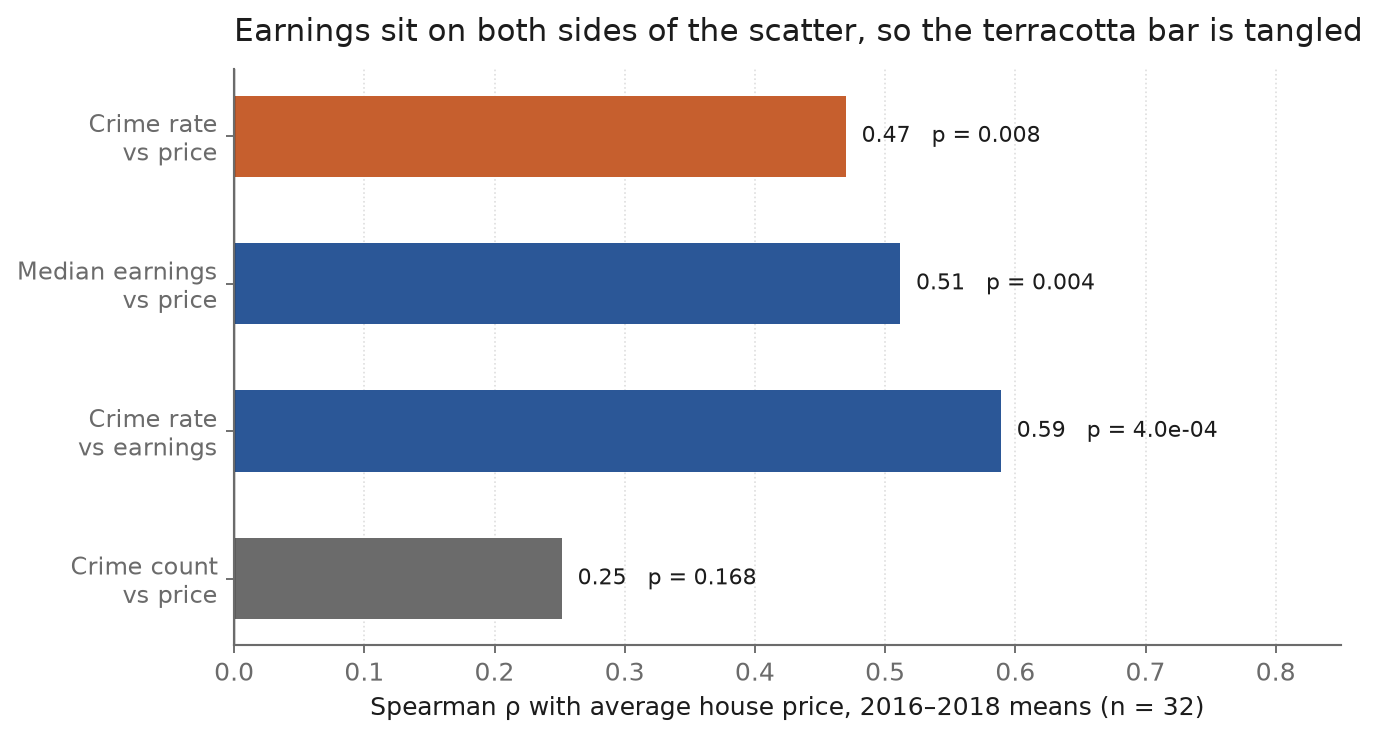

In [11]:
# ============================================================
# 图 2：四根柱，说明「工资同时站在两边」
# ============================================================
labels = ["Crime rate\nvs price", "Median earnings\nvs price",
          "Crime rate\nvs earnings", "Crime count\nvs price"]
vals = [spearman(cs["rate"], cs["price"]), spearman(cs["salary"], cs["price"]),
        spearman(cs["rate"], cs["salary"]), spearman(cs["counts"], cs["price"])]
ps   = [perm_p(cs["rate"], cs["price"], n=5000, seed=7),
        perm_p(cs["salary"], cs["price"], n=5000, seed=7),
        perm_p(cs["rate"], cs["salary"], n=5000, seed=7),
        perm_p(cs["counts"], cs["price"], n=5000, seed=7)]
colors = [TERRA, BLUE, BLUE, MUTED]

fig, ax = plt.subplots(figsize=(8.4, 4.4))
yp = np.arange(len(labels))[::-1]
ax.barh(yp, vals, height=0.55, color=colors, edgecolor="none")
ax.axvline(0, color=INK, lw=1.0)
for yy, v, p in zip(yp, vals, ps):
    ax.text(v + 0.012, yy, f"{v:.2f}   p = {p:.1e}" if p < 0.001 else f"{v:.2f}   p = {p:.3f}",
            va="center", fontsize=9.5)
ax.set_yticks(yp); ax.set_yticklabels(labels, fontsize=10)
ax.set_xlim(0, 0.85)
ax.set_xlabel("Spearman ρ with average house price, 2016–2018 means (n = 32)")
ax.set_title("Earnings sit on both sides of the scatter, so the terracotta bar is tangled",
             loc="left", pad=12)
tidy(ax, "x")
save(fig, "fig2_bars.png")

saved fig3_heatmap.png


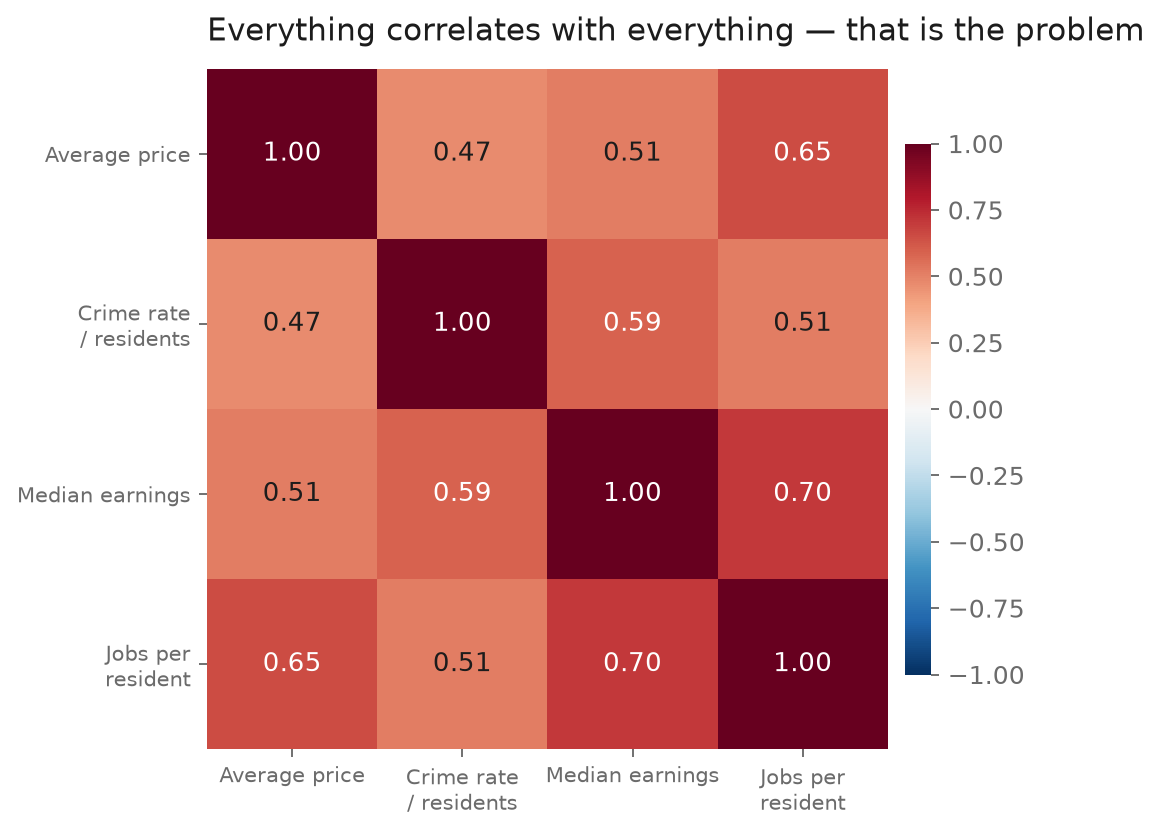

,Average price,Crime rate\n/ residents,Median earnings,Jobs per\nresident
Average price,1.00,0.47,0.51,0.65
Crime rate\n/ residents,0.47,1.00,0.59,0.51
Median earnings,0.51,0.59,1.00,0.70
Jobs per\nresident,0.65,0.51,0.70,1.00


In [12]:
# ============================================================
# 图 3：四变量秩相关矩阵 —— 工资和就业密度相关 0.70
# 它们几乎在测量同一个东西，这就是「共线性」
# ============================================================
cols = ["price", "rate", "salary", "jobs_ratio"]
names = ["Average price", "Crime rate\n/ residents", "Median earnings", "Jobs per\nresident"]
M = pd.DataFrame(
    [[cs[a].rank().corr(cs[b].rank()) for b in cols] for a in cols],
    index=names, columns=names,
)

fig, ax = plt.subplots(figsize=(6.4, 5.2))
im = ax.imshow(M.values.astype(float), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(4)); ax.set_yticks(range(4))
ax.set_xticklabels(names, fontsize=9); ax.set_yticklabels(names, fontsize=9)
for i in range(4):
    for j in range(4):
        v = M.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=11,
                color="white" if abs(v) > 0.55 else INK)
ax.set_title("Everything correlates with everything — that is the problem", loc="left", pad=12)
for s in ax.spines.values():
    s.set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.78, pad=0.02).outline.set_visible(False)
save(fig, "fig3_heatmap.png")
M.round(2)

## 6. The denominator sweep

A crime **rate** needs an exposure. The draft uses residents. But crime is recorded where
it happens, and central London holds far more workers and visitors than residents:
Westminster has **3.07 jobs per resident**, against a borough median of 0.46.

So replace the exposure with `residents + k × jobs` and let `k` run from 0 to 2. The
point is not that one `k` is correct — it is that the sign of the answer depends on the
choice.

In [13]:
# ============================================================
# 分母敏感性：分母 = 居民数 + k × 岗位数，k 从 0 扫到 2
# k=0 就是原口径；k=1 等于「一个岗位折一个白天暴露的人」
# ============================================================
ks = [round(0.1 * i, 1) for i in range(0, 21)]
curve = []
for k in ks:
    rate_k = cs["counts"] / (cs["pop"] + k * cs["jobs"]) * 1000
    curve.append((k, spearman(rate_k, cs["price"])))

curve_df = pd.DataFrame(curve, columns=["k", "rho"]).round(3)
print(curve_df.to_string(index=False))

# 线性插值找过零点
zero = None
for i in range(len(curve) - 1):
    (k0, r0), (k1, r1) = curve[i], curve[i + 1]
    if r0 * r1 < 0:
        zero = k0 + (0 - r0) * (k1 - k0) / (r1 - r0)
        break
print(f"\nsign flips at k ≈ {zero:.2f}" if zero else "\nno sign flip on this grid")

  k    rho
0.0  0.469
0.1  0.469
0.2  0.452
0.3  0.434
0.4  0.410
0.5  0.367
0.6  0.315
0.7  0.284
0.8  0.202
0.9  0.125
1.0  0.084
1.1  0.042
1.2  0.006
1.3 -0.034
1.4 -0.064
1.5 -0.112
1.6 -0.116
1.7 -0.141
1.8 -0.159
1.9 -0.172
2.0 -0.197

sign flips at k ≈ 1.22


saved fig4_denominator_curve.png


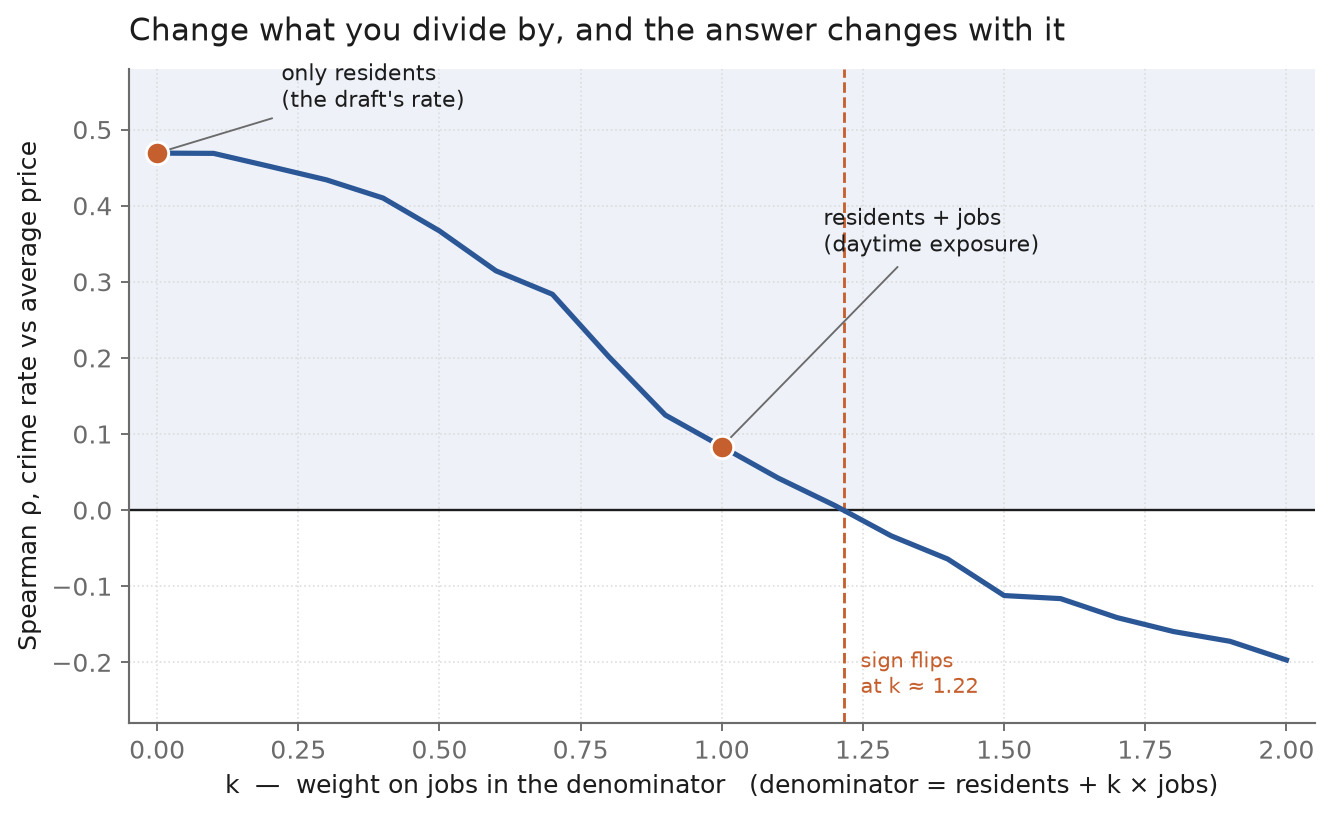

In [14]:
# ============================================================
# 图 4（核心图）：rho 随 k 变化
# ============================================================
ks_ = np.array([c[0] for c in curve])
rhos_ = np.array([c[1] for c in curve])

fig, ax = plt.subplots(figsize=(9.0, 5.0))
ax.axhspan(0, 0.62, color="#eef2f8", zorder=0)
ax.plot(ks_, rhos_, color=BLUE, lw=2.2, zorder=3)
ax.axhline(0, color=INK, lw=1.0, zorder=2)
ax.axvline(zero, color=TERRA, ls="--", lw=1.2, zorder=2)
ax.scatter([0, 1.0], [rhos_[0], rhos_[10]], s=90, color=TERRA, zorder=4,
           edgecolor="white", linewidth=1.2)
ax.annotate("only residents\n(the draft's rate)", xy=(0, rhos_[0]), xytext=(0.22, 0.53),
            fontsize=9.2, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
ax.annotate("residents + jobs\n(daytime exposure)", xy=(1.0, rhos_[10]), xytext=(1.18, 0.34),
            fontsize=9.2, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
ax.text(zero + 0.03, -0.24, f"sign flips\nat k ≈ {zero:.2f}", fontsize=9, color=TERRA)
ax.set_xlabel("k  —  weight on jobs in the denominator   (denominator = residents + k × jobs)")
ax.set_ylabel("Spearman ρ, crime rate vs average price")
ax.set_title("Change what you divide by, and the answer changes with it", loc="left", pad=12)
ax.set_xlim(-0.05, 2.05); ax.set_ylim(-0.28, 0.58)
tidy(ax)
save(fig, "fig4_denominator_curve.png")

## 7. Inner and outer London

The same 32 boroughs, split by geography. Pooled, the association is one number; split,
the two halves point in opposite directions. This is the ecological version of a
Simpson's reversal.

In [15]:
# ============================================================
# 内外城分层：n=11 与 n=21，两组的斜率方向相反
# ============================================================
for name, sub in (("inner", cs[cs["inner"]]), ("outer", cs[~cs["inner"]])):
    rho = spearman(sub["rate"], sub["price"])
    print(f"{name:5s} n = {len(sub):2d}   rho = {rho:+.3f}   perm p = "
          f"{perm_p(sub['rate'], sub['price'], n=5000, seed=11):.3f}")
print(f"pooled n = {len(cs):2d}   rho = {spearman(cs['rate'], cs['price']):+.3f}")

inner n = 11   rho = +0.827   perm p = 0.002


outer n = 21   rho = -0.294   perm p = 0.201
pooled n = 32   rho = +0.470


saved fig5_inner_outer.png


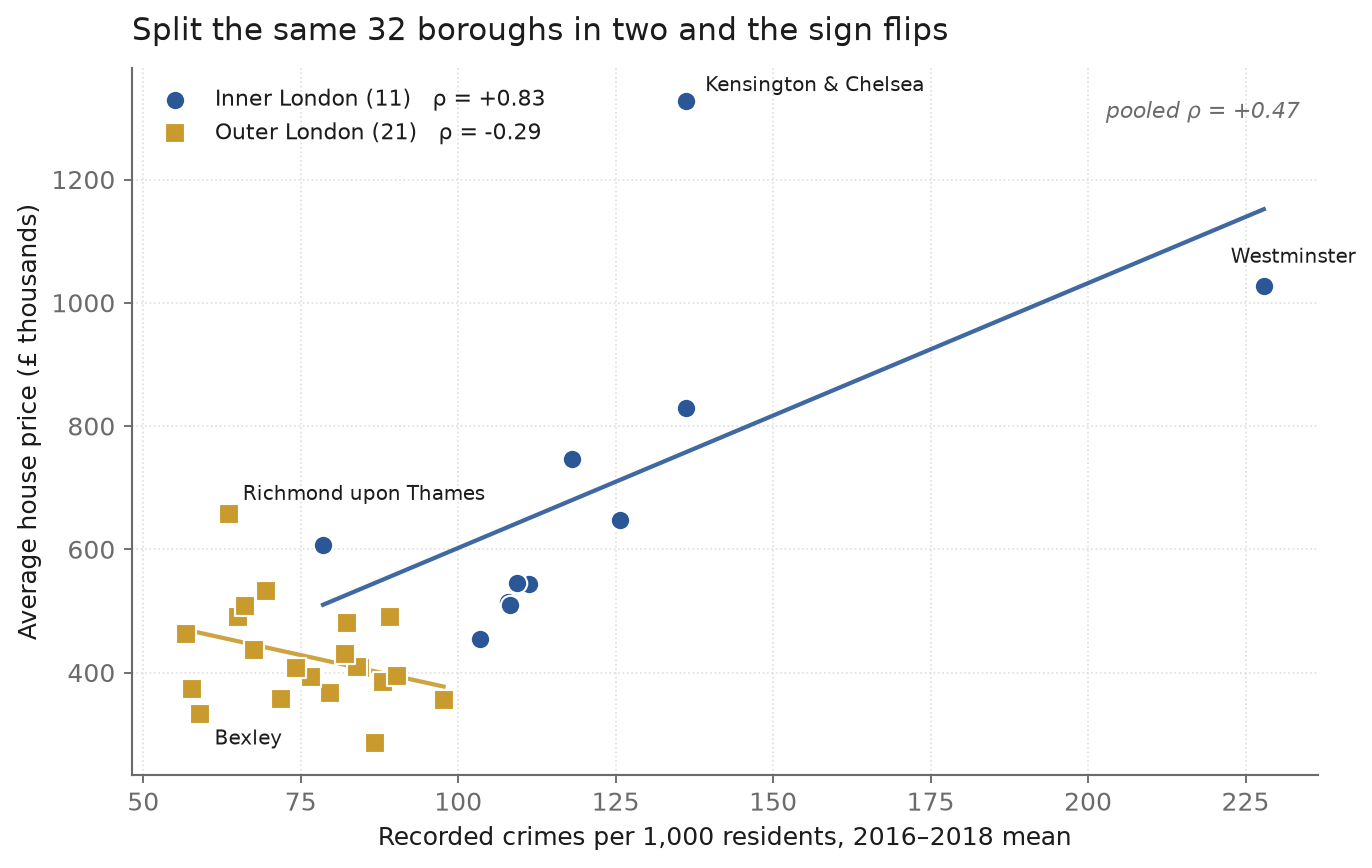

In [16]:
# ============================================================
# 图 5：内城蓝圆 / 外城金方，各画一条趋势线
# ============================================================
fig, ax = plt.subplots(figsize=(9.0, 5.4))
for mask, color, marker, lab in [
    (cs["inner"], BLUE, "o", "Inner London (11)"),
    (~cs["inner"], GOLD, "s", "Outer London (21)"),
]:
    sub = cs[mask]
    rho = spearman(sub["rate"], sub["price"])
    ax.scatter(sub["rate"], sub["price"] / 1000, s=68, color=color, marker=marker,
               edgecolor="white", linewidth=0.9, zorder=3,
               label=f"{lab}   ρ = {rho:+.2f}")
    xs, ys = ols_line(sub["rate"], sub["price"] / 1000)
    ax.plot(xs, ys, color=color, lw=1.8, alpha=0.9, zorder=2)

for name, dx, dy in [("westminster", -14, 10), ("kensington and chelsea", 8, 4),
                     ("bexley", 6, -13), ("richmond upon thames", 6, 6)]:
    r = cs[cs["area"] == name].iloc[0]
    ax.annotate(pretty(name), xy=(r["rate"], r["price"] / 1000), xytext=(dx, dy),
                textcoords="offset points", fontsize=8.5)
ax.set_xlabel("Recorded crimes per 1,000 residents, 2016–2018 mean")
ax.set_ylabel("Average house price (£ thousands)")
ax.set_title("Split the same 32 boroughs in two and the sign flips", loc="left", pad=12)
ax.text(0.985, 0.93, "pooled ρ = +0.47", transform=ax.transAxes, ha="right",
        fontsize=9.5, color=MUTED, style="italic")
ax.legend(loc="upper left", fontsize=9.5)
tidy(ax)
save(fig, "fig5_inner_outer.png")

## 8. Within a borough: year-to-year changes

Every comparison so far is **between** places. This one is **within** a place: for each
borough, the change in the crime rate from one year to the next, against the change in
price. Location, transport and everything else that makes a borough permanently
different drops out.

Each borough contributes up to 17 year-pairs, and pairs inside one borough are not
independent, so the interval is clustered by borough.

In [17]:
# ============================================================
# 区内变化：同一区相邻两年的差分
# 注意：不能用普通 p 值，年度对之间同区相关，必须按区做整块 bootstrap
# ============================================================
pp = panel.sort_values(["area", "year"]).copy()
g = pp.groupby("area")
pp["prev_year"] = g["year"].shift(1)
pp["d_rate"] = pp["crime_per_1000"] - g["crime_per_1000"].shift(1)
pp["d_price"] = pp["avg_price"] - g["avg_price"].shift(1)

chg = pp[(pp["year"] - pp["prev_year"]) == 1].dropna(subset=["d_rate", "d_price"]).copy()

r_w = spearman(chg["d_rate"], chg["d_price"])
lo_w, hi_w = boot_ci(chg["d_rate"], chg["d_price"], groups=chg["area"])

print(f"year-pairs       : {len(chg)}")
print(f"boroughs         : {chg['area'].nunique()}")
print(f"rho              : {r_w:.3f}")
print(f"cluster boot 95% : [{lo_w:.3f}, {hi_w:.3f}]")
print(f"rho^2            : {r_w ** 2:.3f}")

year-pairs       : 552
boroughs         : 33
rho              : 0.144
cluster boot 95% : [0.068, 0.220]
rho^2            : 0.021


saved fig6_within.png


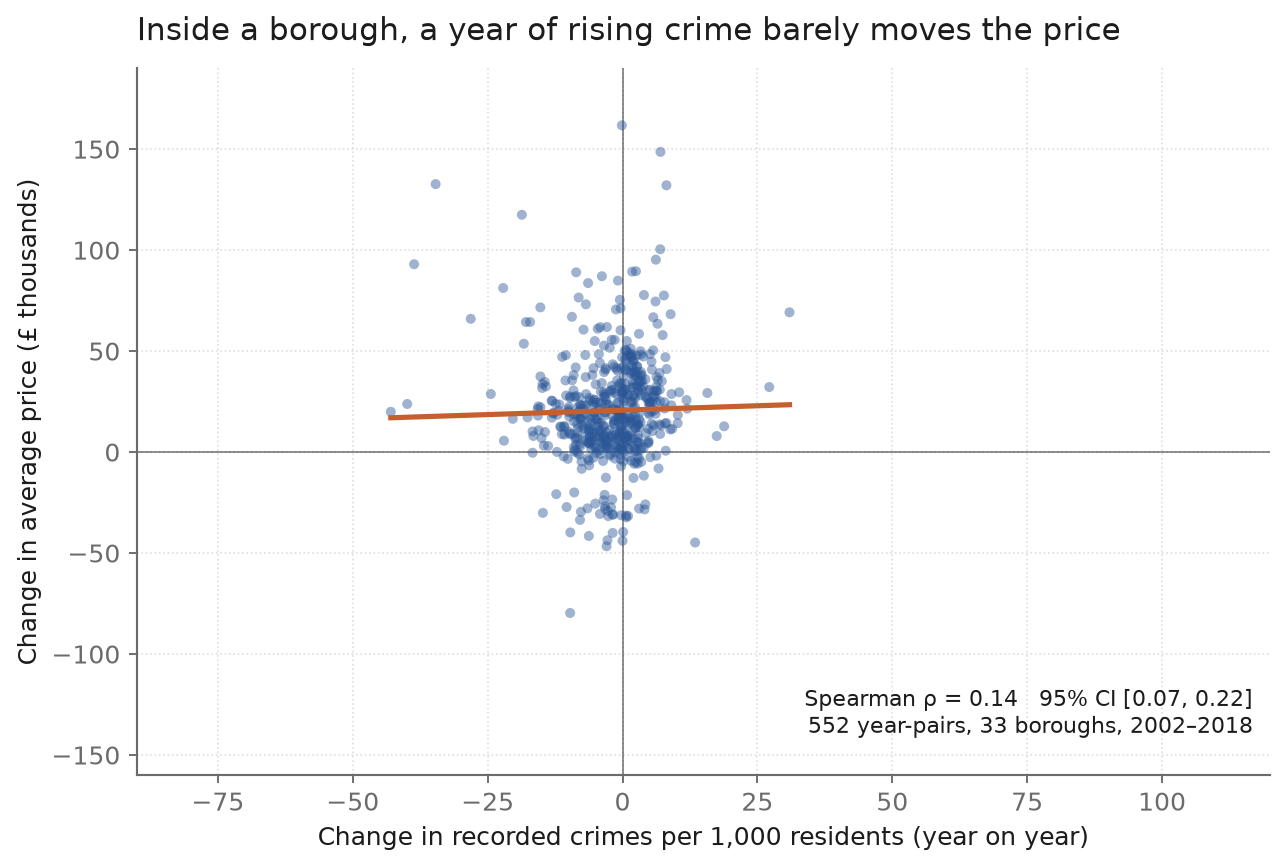

In [18]:
# ============================================================
# 图 6：552 个年度对，趋势线几乎水平
# ============================================================
fig, ax = plt.subplots(figsize=(8.6, 5.4))
ax.axhline(0, color=INK, lw=0.8, alpha=0.5, zorder=1)
ax.axvline(0, color=INK, lw=0.8, alpha=0.5, zorder=1)
ax.scatter(chg["d_rate"], chg["d_price"] / 1000, s=18, color=BLUE, alpha=0.45,
           edgecolor="none", zorder=3)
xs, ys = ols_line(chg["d_rate"], chg["d_price"] / 1000)
ax.plot(xs, ys, color=TERRA, lw=2.2, zorder=4)
ax.set_xlim(-90, 120); ax.set_ylim(-160, 190)
ax.set_xlabel("Change in recorded crimes per 1,000 residents (year on year)")
ax.set_ylabel("Change in average price (£ thousands)")
ax.set_title("Inside a borough, a year of rising crime barely moves the price", loc="left", pad=12)
ax.text(0.985, 0.06,
        f"Spearman ρ = {r_w:.2f}   95% CI [{lo_w:.2f}, {hi_w:.2f}]\n"
        f"{len(chg)} year-pairs, {chg['area'].nunique()} boroughs, 2002–2018",
        transform=ax.transAxes, ha="right", fontsize=9.5)
tidy(ax)
save(fig, "fig6_within.png")

## 9. Lead and lag

If crime pushed prices, this year's change in crime should line up with **next** year's
change in price. The reverse ordering is a crude check on the direction.

In [19]:
# ============================================================
# 领先/滞后：把两个差分序列错开一年再算相关
# 注意：这只说明时间先后，不构成因果
# ============================================================
lag = pp.sort_values(["area", "year"]).copy()
lag["d_price_next"] = lag.groupby("area")["d_price"].shift(-1)
lag["d_rate_next"] = lag.groupby("area")["d_rate"].shift(-1)

a1 = lag.dropna(subset=["d_rate", "d_price_next"])
a2 = lag.dropna(subset=["d_price", "d_rate_next"])
print(f"d crime(t) -> d price(t+1): rho = {spearman(a1['d_rate'], a1['d_price_next']):+.3f}  (n = {len(a1)})")
print(f"d price(t) -> d crime(t+1): rho = {spearman(a2['d_price'], a2['d_rate_next']):+.3f}  (n = {len(a2)})")

d crime(t) -> d price(t+1): rho = -0.074  (n = 519)
d price(t) -> d crime(t+1): rho = +0.223  (n = 519)


## 10. Leave-one-out

Westminster sits far from the rest of the cloud. Drop each borough in turn and see how
far the pooled correlation moves.

In [20]:
# ============================================================
# 逐区剔除：检验结果是否被单个极值点撑起来
# ============================================================
loo = sorted(
    [(a, spearman(cs.loc[cs["area"] != a, "rate"], cs.loc[cs["area"] != a, "price"]))
     for a in cs["area"]],
    key=lambda t: t[1],
)
print(f"range: {loo[0][1]:.3f} – {loo[-1][1]:.3f}")
print(f"lowest  after dropping {loo[0][0]}  ({loo[0][1]:.3f})")
print(f"highest after dropping {loo[-1][0]}  ({loo[-1][1]:.3f})")
print(f"Westminster removed   {dict(loo)['westminster']:.3f}")

range: 0.417 – 0.546
lowest  after dropping camden  (0.417)
highest after dropping richmond upon thames  (0.546)
Westminster removed   0.417


saved fig8_loo.png


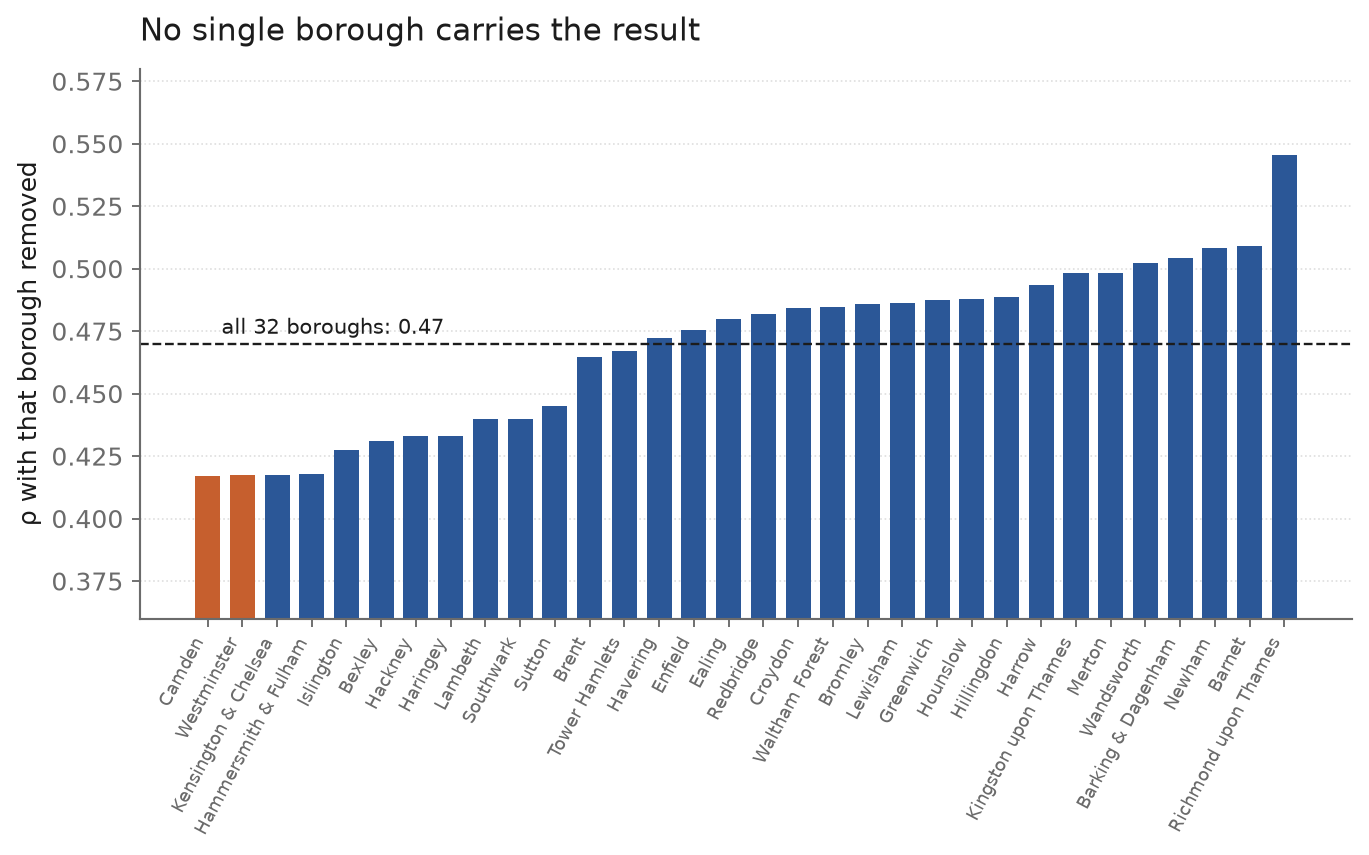

In [21]:
# ============================================================
# 图 8：逐区剔除后的 rho，虚线是全样本 0.47
# ============================================================
loo = sorted(loo, key=lambda t: t[1])
fig, ax = plt.subplots(figsize=(9.2, 4.2))
vals = [v for _, v in loo]
ax.bar(range(len(vals)), vals,
       color=[TERRA if pretty(a) in ("Camden", "Westminster") else BLUE for a, _ in loo],
       width=0.72)
ax.axhline(spearman(cs["rate"], cs["price"]), color=INK, ls="--", lw=1.0)
ax.text(0.4, spearman(cs["rate"], cs["price"]) + 0.002, "all 32 boroughs: 0.47",
        ha="left", va="bottom", fontsize=9)
ax.set_xticks(range(len(vals)))
ax.set_xticklabels([pretty(a) for a, _ in loo], rotation=62, ha="right", fontsize=7.6)
ax.set_ylim(0.36, 0.58)
ax.set_ylabel("ρ with that borough removed")
ax.set_title("No single borough carries the result", loc="left", pad=12)
tidy(ax, "y")
save(fig, "fig8_loo.png")

## 11. Offence types

The monthly file carries one crime total. The MPS borough file splits it into eleven
categories. Same 32 boroughs, same three years, same denominator (residents), so the
only thing that changes is **which offence** is being counted.

Two findings matter. Burglary tracks price strongly; criminal damage sits at zero and
turns negative once earnings are held constant. Gibbons (2004) reported the same split
for London.

In [22]:
# ============================================================
# 读 MPS 分罪名表（宽表：一行 = 一个区的一个罪名，列 = 月份）
# ============================================================
mps_raw = pd.read_csv(DATA / "MPS_Borough_Level_Crime_Historical.csv", encoding="utf-8-sig")
mps_raw.columns = [str(c).strip() for c in mps_raw.columns]

month_cols = [c for c in mps_raw.columns if c.isdigit() and len(c) == 6]
want = [c for c in month_cols if c[:4] in ("2016", "2017", "2018")]

# 月份列一次性转成数值，再横向求和 → 每行一个区一个罪名三年的总案发数
counts = mps_raw[want].apply(pd.to_numeric, errors="coerce").sum(axis=1)

# 重新组装成干净的表，避免在原表上反复插列（会触发碎片化警告）
mps = pd.DataFrame({
    "offence": mps_raw["MajorText"].str.strip(),
    "minor": mps_raw["MinorText"].str.strip(),
    "area": mps_raw["BoroughName"].str.strip().str.lower(),
    "_total": counts,
})

print("months used:", len(want), f"({want[0]} to {want[-1]})")
print("rows:", len(mps), "| offence categories:", mps["offence"].nunique())
mps.head()

months used: 36 (201601 to 201812)
rows: 1094 | offence categories: 13


,offence,minor,area,_total
0,ARSON AND CRIMINAL DAMAGE,ARSON,barking and dagenham,208
1,ARSON AND CRIMINAL DAMAGE,CRIMINAL DAMAGE,barking and dagenham,4802
2,BURGLARY,BURGLARY BUSINESS AND COMMUNITY,barking and dagenham,1184
3,BURGLARY,DOMESTIC BURGLARY,barking and dagenham,3345
4,BURGLARY,RES BURGLARY OF A HOME,barking and dagenham,0


In [23]:
# ============================================================
# 按罪名汇总到区，再和房价算秩相关
# 同时给出「控工资后」和「换白天人口分母后」两列做对照
# ============================================================
types = (mps.groupby(["offence", "area"], as_index=False)["_total"].sum())

pop3 = panel[panel["year"].between(2016, 2018)].groupby("area")["population_size"].sum()
job3 = panel[panel["year"].between(2016, 2018)].groupby("area")["number_of_jobs"].sum()
pri = dict(zip(cs["area"], cs["price"]))
sal = dict(zip(cs["area"], cs["salary"]))

rows = []
for off, g_ in types.groupby("offence"):
    s = g_.set_index("area")["_total"]
    areas = [a for a in s.index if a in pri and a in pop3.index and pop3[a] > 0]
    if len(areas) < 20 or s.loc[areas].sum() == 0:
        continue                                    # 空表（Fraud）直接跳过
    cnt = s.loc[areas].to_numpy(dtype=float)
    pv = np.array([pri[a] for a in areas])
    sv = np.array([sal[a] for a in areas])
    den = np.array([pop3[a] for a in areas])
    den2 = den + np.array([job3[a] for a in areas])
    rows.append({
        "offence": off,
        "n": len(areas),
        "rho_price": round(spearman(cnt / den, pv), 3),
        "rho_price_earnings": round(partial_spearman(cnt / den, pv, sv), 3),
        "rho_earnings": round(spearman(cnt / den, sv), 3),
        "rho_price_jobsadj": round(spearman(cnt / den2, pv), 3),
    })

offence = pd.DataFrame(rows).sort_values("rho_price", ascending=False).reset_index(drop=True)
offence

,offence,n,rho_price,rho_price_earnings,rho_earnings,rho_price_jobsadj
0,BURGLARY,32,0.742,0.650,0.514,0.094
1,THEFT,32,0.638,0.458,0.692,0.563
2,PUBLIC ORDER OFFENCES,32,0.516,0.275,0.662,0.102
3,SEXUAL OFFENCES,32,0.422,0.162,0.608,-0.243
4,DRUG OFFENCES,32,0.384,0.156,0.528,0.118
5,ROBBERY,32,0.364,0.201,0.404,0.158
6,POSSESSION OF WEAPONS,32,0.314,0.107,0.455,-0.058
7,VEHICLE OFFENCES,32,0.310,0.260,0.175,-0.179
8,VIOLENCE AGAINST THE PERSON,32,0.262,0.031,0.466,-0.429
9,MISCELLANEOUS CRIMES AGAINST SOCIETY,32,0.045,-0.248,0.457,-0.441


saved fig7_offence.png


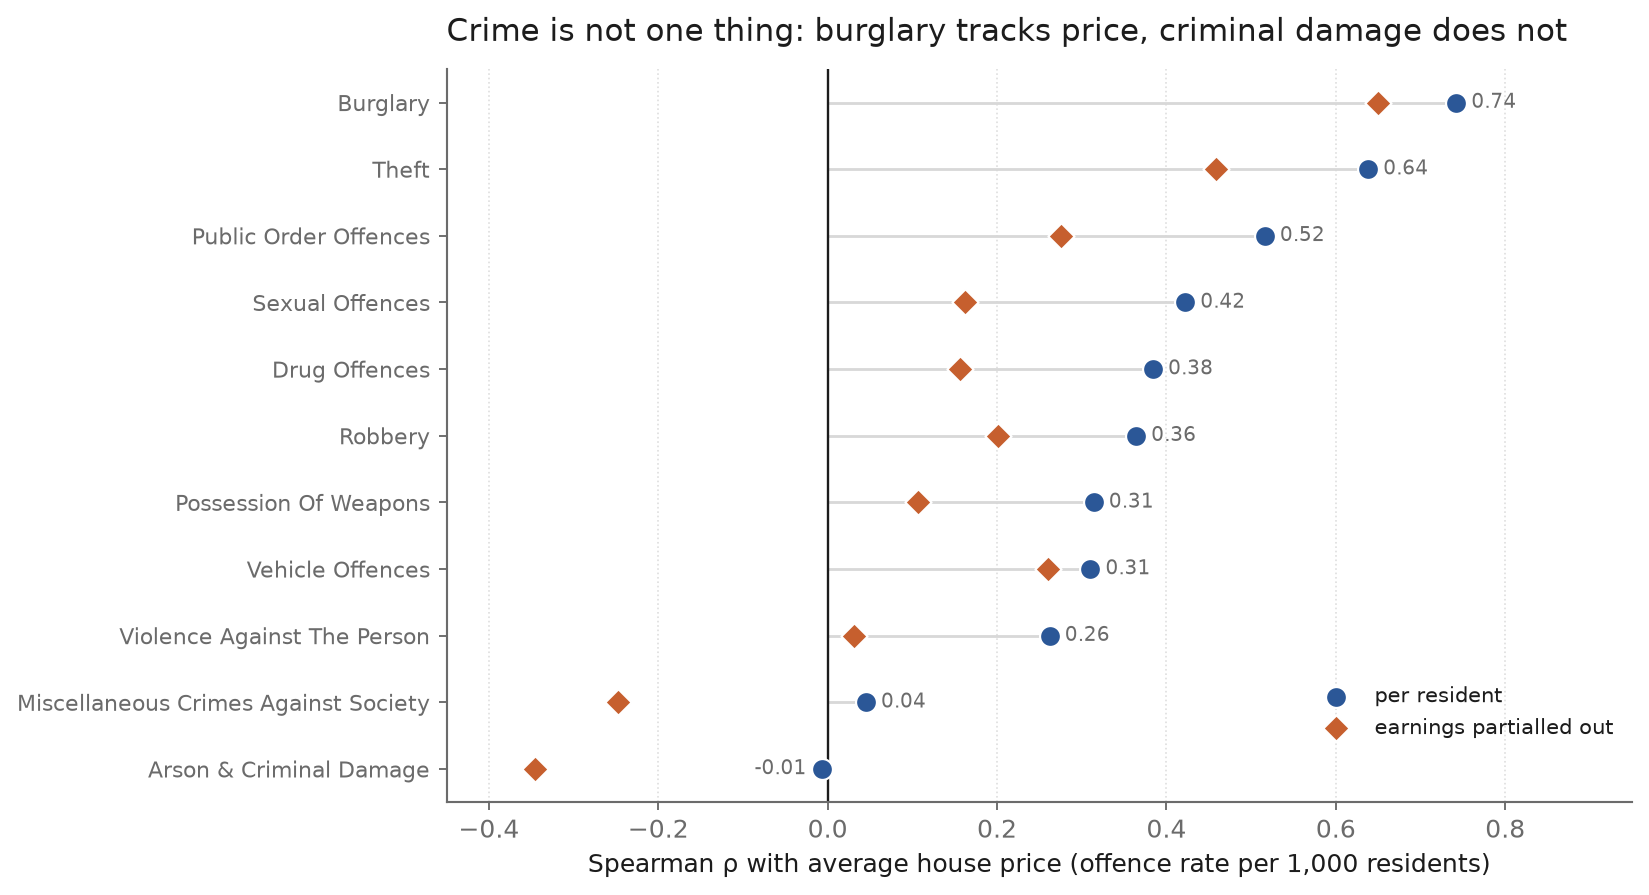

In [24]:
# ============================================================
# 图 7：横轴是相关强度，蓝圆=按居民数，橙菱=控工资后
# ============================================================
o = offence.copy()
o["label"] = o["offence"].map(lambda s: s.title().replace(" And ", " & "))
o = o.sort_values("rho_price")

fig, ax = plt.subplots(figsize=(9.0, 5.6))
ypos = np.arange(len(o))
ax.hlines(ypos, 0, o["rho_price"], color=GRID, lw=1.2, zorder=1)
ax.scatter(o["rho_price"], ypos, s=78, color=BLUE, zorder=3, edgecolor="white",
           linewidth=0.9, label="per resident")
ax.scatter(o["rho_price_earnings"], ypos, s=62, marker="D", color=TERRA, zorder=3,
           edgecolor="white", linewidth=0.9, label="earnings partialled out")
ax.axvline(0, color=INK, lw=1.0)
ax.set_yticks(ypos); ax.set_yticklabels(o["label"], fontsize=9.5)
ax.set_xlabel("Spearman ρ with average house price (offence rate per 1,000 residents)")
ax.set_title("Crime is not one thing: burglary tracks price, criminal damage does not",
             loc="left", pad=12)
ax.set_xlim(-0.45, 0.95)
ax.legend(loc="lower right", fontsize=9, bbox_to_anchor=(1.0, 0.06))
for yy, v in zip(ypos, o["rho_price"]):
    ax.text(v + (0.018 if v >= 0 else -0.018), yy, f"{v:.2f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=8.5, color=MUTED)
tidy(ax, "x")
save(fig, "fig7_offence.png")

## 12. Cross-validation of the two crime totals

The two sources are independent publications. If the panel is right, their totals for
the same 32 boroughs and the same three years should be close.

In [25]:
# ============================================================
# 交叉验证：MPS 分罪名总量 vs Kaggle 月度总量
# 顺带确认 MPS 表里没有 ALL 汇总行，否则会重复计数
# ============================================================
print("minor categories per major offence:")
for k, v in mps.groupby("offence")["minor"].nunique().items():
    print(f"  {k:38s} {v}")

mps_tot = mps[mps["area"].isin(set(cs["area"]))]["_total"].sum()
kag_tot = panel[panel["year"].between(2016, 2018)]["crimes"].sum()
print(f"\nMPS total        : {mps_tot:,.0f}")
print(f"Kaggle total     : {kag_tot:,.0f}")
print(f"ratio (MPS/Kaggle): {mps_tot / kag_tot:.3f}")

minor categories per major offence:
  ARSON AND CRIMINAL DAMAGE              2
  BURGLARY                               4
  DRUG OFFENCES                          2
  FRAUD AND FORGERY                      1
  MISCELLANEOUS CRIMES AGAINST SOCIETY   1
  NFIB FRAUD                             1
  POSSESSION OF WEAPONS                  1
  PUBLIC ORDER OFFENCES                  4
  ROBBERY                                2
  SEXUAL OFFENCES                        2
  THEFT                                  4
  VEHICLE OFFENCES                       4
  VIOLENCE AGAINST THE PERSON            5

MPS total        : 2,390,376
Kaggle total     : 2,423,594
ratio (MPS/Kaggle): 0.986


## 13. Summary

Every comparison the report quotes, in one table.

In [26]:
# ============================================================
# 汇总表：报告里引用的每个数字都在这里
# ============================================================
summary = pd.DataFrame([
    ("cross-section, crime rate vs price",       r_raw,  "the draft's 0.47"),
    ("  earnings partialled out",                r_part, "halves, stays positive"),
    ("crime rate / (residents + jobs) vs price", r_day,  "association nearly gone"),
    ("  earnings partialled out",                r_day_p,""),
    ("inner London (11 boroughs)",               spearman(cs.loc[cs['inner'], 'rate'], cs.loc[cs['inner'], 'price']), "positive and strong"),
    ("outer London (21 boroughs)",               spearman(cs.loc[~cs['inner'], 'rate'], cs.loc[~cs['inner'], 'price']), "negative, not significant"),
    ("within-borough changes",                   r_w,    "near zero"),
    ("burglary vs price",                        offence.set_index('offence').loc['BURGLARY', 'rho_price'], "strongest single offence"),
    ("arson & criminal damage vs price",         offence.set_index('offence').loc['ARSON AND CRIMINAL DAMAGE', 'rho_price'], "essentially zero"),
], columns=["comparison", "spearman", "reading"]).round(3)

summary

,comparison,spearman,reading
0,"cross-section, crime rate vs price",0.470,the draft's 0.47
1,earnings partialled out,0.243,"halves, stays positive"
2,crime rate / (residents + jobs) vs price,0.084,association nearly gone
3,earnings partialled out,0.053,
4,inner London (11 boroughs),0.827,positive and strong
5,outer London (21 boroughs),-0.294,"negative, not significant"
6,within-borough changes,0.144,near zero
7,burglary vs price,0.742,strongest single offence
8,arson & criminal damage vs price,-0.007,essentially zero


### Limitations to carry into the report

* 32 borough means is a small sample. The 95% interval for the baseline correlation is
  roughly **[0.06, 0.76]** — wide enough that "no association" is not ruled out.
* `number_of_jobs` is only a proxy for daytime population. Visitors and commuting
  direction are not counted, so the denominator sweep is a range, not a point estimate.
* The panel ends in 2018 because population is missing for 2019.
* Every coefficient here is an association between borough averages. Nothing in this
  notebook identifies a causal effect, and no result describes a street or a household
  (Robinson, 1950).
* The MPS offence split is a cross-section only. Reading it as "burglary pushes prices
  up" reverses the plausible mechanism: burglars choose areas where property is worth
  stealing.